# Chronos-2 Electricity Forecasting: Data Preparation

## Overview

This notebook handles the preparation of the hourly Electricity dataset for Chronos-2 forecasting.

The dataset contains 321 electricity customer time series, with 26,304 hourly observations per series.

The main tasks performed in this notebook are:

- Loading and parsing the Electricity dataset.
- Inspecting the structure and statistical properties of the time series.
- Exploring electricity consumption patterns through visualisations.
- Splitting each series chronologically into training, validation, and test sets.
- Saving the prepared dataset splits for subsequent model evaluation and fine-tuning.

## 1. Environment Setup and Dataset Loading

Google Drive is mounted to provide access to the project directory and store the prepared dataset splits.

The hourly Electricity dataset is uploaded into the Colab runtime for processing. The required Python libraries are also imported for data manipulation, numerical operations, and visualisation.

In [1]:
from google.colab import drive, files
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

save_dir = "/content/drive/MyDrive/Chronos2_Finetune"
os.makedirs(save_dir, exist_ok=True)

print("Project folder ready")

Project folder ready


In [3]:
uploaded = files.upload()

Saving electricity_hourly_dataset.ts to electricity_hourly_dataset.ts


In [5]:
from pathlib import Path

file_path = Path("/content/electricity_hourly_dataset.ts")

print("File exists:", file_path.exists())

if file_path.exists():
    print(file_path.read_text(errors="replace")[:3000])

File exists: True
# Dataset Information
# The electricity dataset represents the electricity consumption of 370 clients recorded in 15-minutes periods in Kilowatt (kW) from 2011 to 2014.
# This file contains an aggregated version of the original dataset used by Lai et al. (2017).
# This contains 321 hourly time series from 2012 to 2014.
#
# For more details, please refer to
# UCI, 2020. Electricityloaddiagrams20112014 data set, uci machine learning repository. Accessed:  2020-04-30. URL https://archive.ics.uci.edu/ml/datasets/ElectricityLoadDiagrams20112014
# Lai, G., 2017. multivariate-time-series-data. https://github.com/laiguokun/multivariate-time-series-data, accessed:  2020-05-04
# Lai, G., Chang, W., Yang, Y., Liu, H., 2017. Modeling long and short-term temporal patterns with deep neural networks. CoRR abs/1703.07015.URL http://arxiv.org/abs/1703.07015
#
@relation Electricity
@attribute series_name string
@attribute start_timestamp date
@frequency hourly
@missing false
@equalleng

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 2. Parsing the Dataset

The Electricity dataset is provided in the `.ts` (Time Series) format.

The file is read line by line, and its metadata and comments are excluded to extract the individual customer time series.

Each data entry contains:
- A unique customer series ID.
- The starting timestamp.
- The electricity consumption observations.

The dataset contains 321 hourly time series, each with 26,304 observations.

In [6]:
with open(file_path, "r") as f:
    lines = f.readlines()

data_lines = [
    line.strip() for line in lines
    if line.strip() and not line.strip().startswith("#")
    and ":" in line
    and line.strip().split(":")[0].startswith("T")
]

print("Number of series:", len(data_lines))
print("\nFirst series preview:")
print(data_lines[0][:150])

first_series = data_lines[0].split(":")
values = first_series[2].split(",")

print("\nFirst series ID:", first_series[0])
print("Number of observations:", len(values))
print("First 10 values:", values[:10])

Number of series: 321

First series preview:
T1:2012-01-01 00-00-01:14,18,21,20,22,20,20,20,13,11,64,53,26,10,28,61,12,33,74,22,19,74,60,46,16,16,19,16,18,16,15,14,43,70,67,68,95,66,88,67,92,51,4

First series ID: T1
Number of observations: 26304
First 10 values: ['14', '18', '21', '20', '22', '20', '20', '20', '13', '11']


## 3. Data Inspection and Exploratory Data Analysis

After parsing the dataset, the individual electricity consumption series are inspected to understand their structure and statistical properties.

This section includes:

- Verifying the number of customer time series and observations.
- Examining descriptive statistics of electricity consumption.
- Visualising selected customer time series.
- Comparing consumption patterns across different customers.

The exploratory analysis provides an overview of the dataset before preparing it for model training and evaluation.

In [8]:
series_data = []

for line in data_lines:
    series_id, start_date, values_str = line.split(":", 2)

    values = np.array(
        values_str.split(","),
        dtype=np.float32
    )

    series_data.append({
        "series_id": series_id,
        "start_date": start_date,
        "values": values
    })

df = pd.DataFrame(series_data)

print("Shape:", df.shape)

print("Total series:", len(series_data))
print("First series:", series_data[0]["series_id"])
print("Array shape:", series_data[0]["values"].shape)
print("Data type:", series_data[0]["values"].dtype)

Shape: (321, 3)
Total series: 321
First series: T1
Array shape: (26304,)
Data type: float32


In [9]:
all_values = np.concatenate([
    item["values"] for item in series_data
])

print("Minimum:", all_values.min())
print("Maximum:", all_values.max())
print("Mean:", all_values.mean())
print("Standard deviation:", all_values.std())
print("Missing values:", np.isnan(all_values).sum())

Minimum: 0.0
Maximum: 764000.0
Mean: 2538.7917
Standard deviation: 15027.57
Missing values: 0


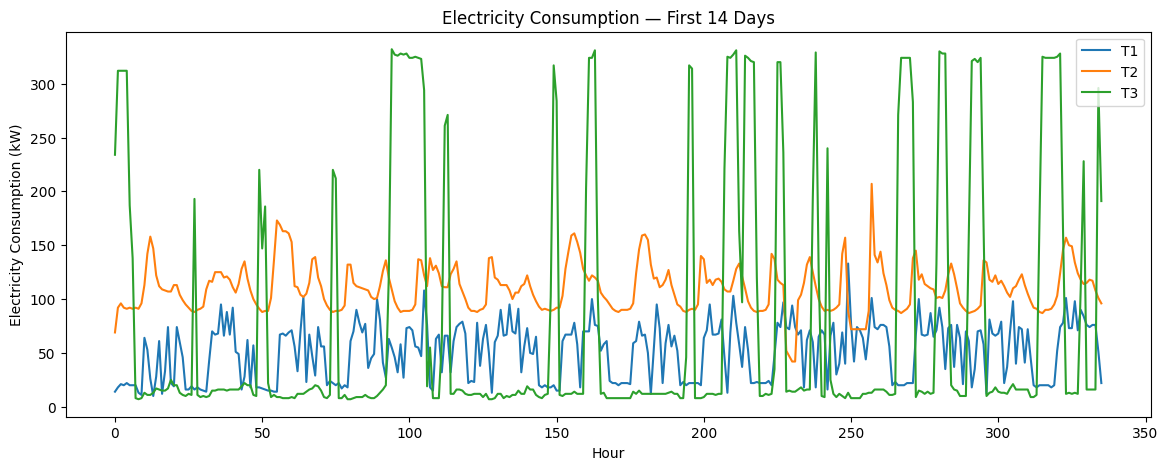

In [10]:
plt.figure(figsize=(14, 5))
for item in series_data[:3]:

    # Plot the first 14 days (24 hours × 14 days = 336 observations)
    # Use the series ID as the label for identification in the legend
    plt.plot(
        item["values"][:24 * 14],
        label=item["series_id"]
    )

plt.title("Electricity Consumption — First 14 Days")
plt.xlabel("Hour")
plt.ylabel("Electricity Consumption (kW)")
plt.legend()
plt.show()

In [11]:
# Compare the consumption distributions across the 321 electricity series
series_stats = pd.DataFrame([
    {
        "series_id": item["series_id"],
        "mean": item["values"].mean(),
        "std": item["values"].std(),
        "min": item["values"].min(),
        "max": item["values"].max()
    }
    for item in series_data
])

print(series_stats.describe())

                mean            std         min            max
count     321.000000     321.000000  321.000000     321.000000
mean     2538.791748    1139.722168    2.928349    6723.358398
std     12479.286133    8336.542969    7.242105   44481.257812
min        10.627395       8.541787    0.000000      85.000000
25%       288.346497     105.845963    0.000000     691.000000
50%       591.950378     206.605209    0.000000    1317.000000
75%      1425.515991     522.713867    4.000000    3161.000000
max    200529.125000  146051.828125   64.000000  764000.000000


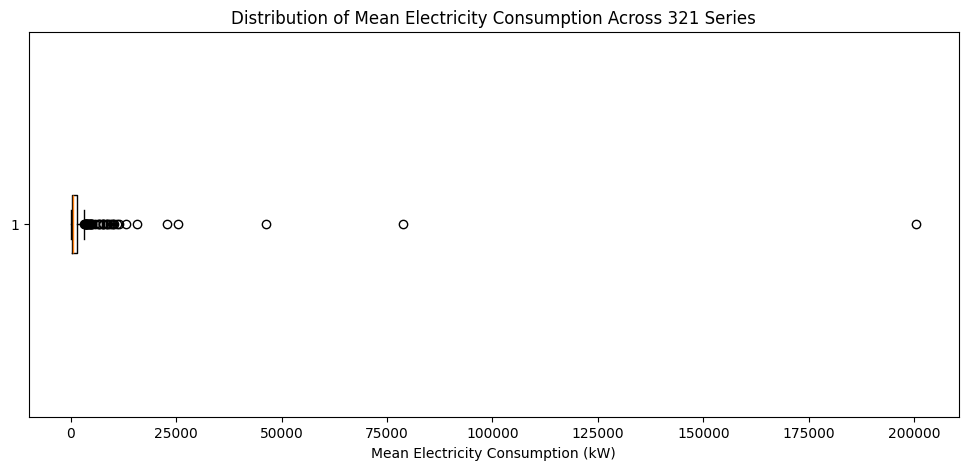

In [12]:
plt.figure(figsize=(12, 5))

plt.boxplot(series_stats["mean"], vert=False)

plt.title("Distribution of Mean Electricity Consumption Across 321 Series")
plt.xlabel("Mean Electricity Consumption (kW)")

plt.show()

In [13]:
# Identify the 10 series with the highest average consumption
top_series = series_stats.nlargest(10, "mean")

print(top_series.to_string(index=False))

series_id          mean           std  min      max
     T314 200529.125000 146051.828125  0.0 764000.0
     T156  78701.093750  25938.847656  0.0 203001.0
     T237  46173.425781  11504.755859  0.0  78721.0
     T168  25457.794922   7258.594727  0.0  48843.0
     T187  22692.117188   7763.625000  0.0  41318.0
     T316  15678.371094   9737.835938  0.0  39728.0
     T291  13026.765625   7311.215332  0.0  39529.0
     T180  11524.401367   4668.364258  0.0  25420.0
     T120  10938.340820   1032.155029  0.0  21339.0
     T200  10326.177734   2958.041504  0.0  18521.0


In [14]:
# Retrieve the series with the highest average consumption
highest_series_id = top_series.iloc[0]["series_id"]

highest_series = next(
    item for item in series_data
    if item["series_id"] == highest_series_id
)

print("Series:", highest_series_id)
print("Mean:", highest_series["values"].mean())
print("Minimum:", highest_series["values"].min())
print("Maximum:", highest_series["values"].max())

Series: T314
Mean: 200529.12
Minimum: 0.0
Maximum: 764000.0


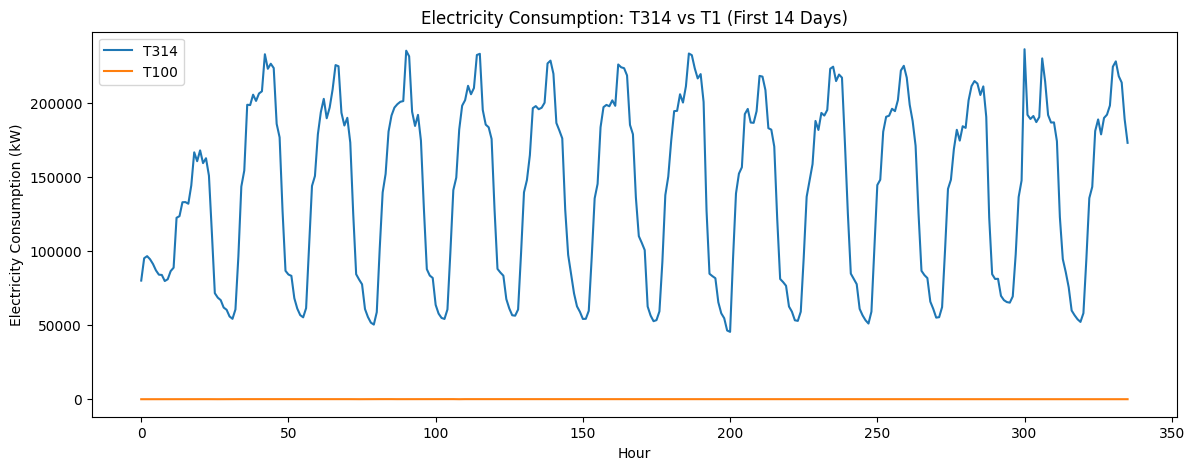

In [15]:
# Compare the consumption patterns of the highest-mean series and a typical series
plt.figure(figsize=(14, 5))

plt.plot(
    highest_series["values"][:24 * 14],
    label="T314"
)

plt.plot(
    series_data[0]["values"][:24 * 14],
    label="T100"
)

plt.title("Electricity Consumption: T314 vs T1 (First 14 Days)")
plt.xlabel("Hour")
plt.ylabel("Electricity Consumption (kW)")
plt.legend()

plt.show()

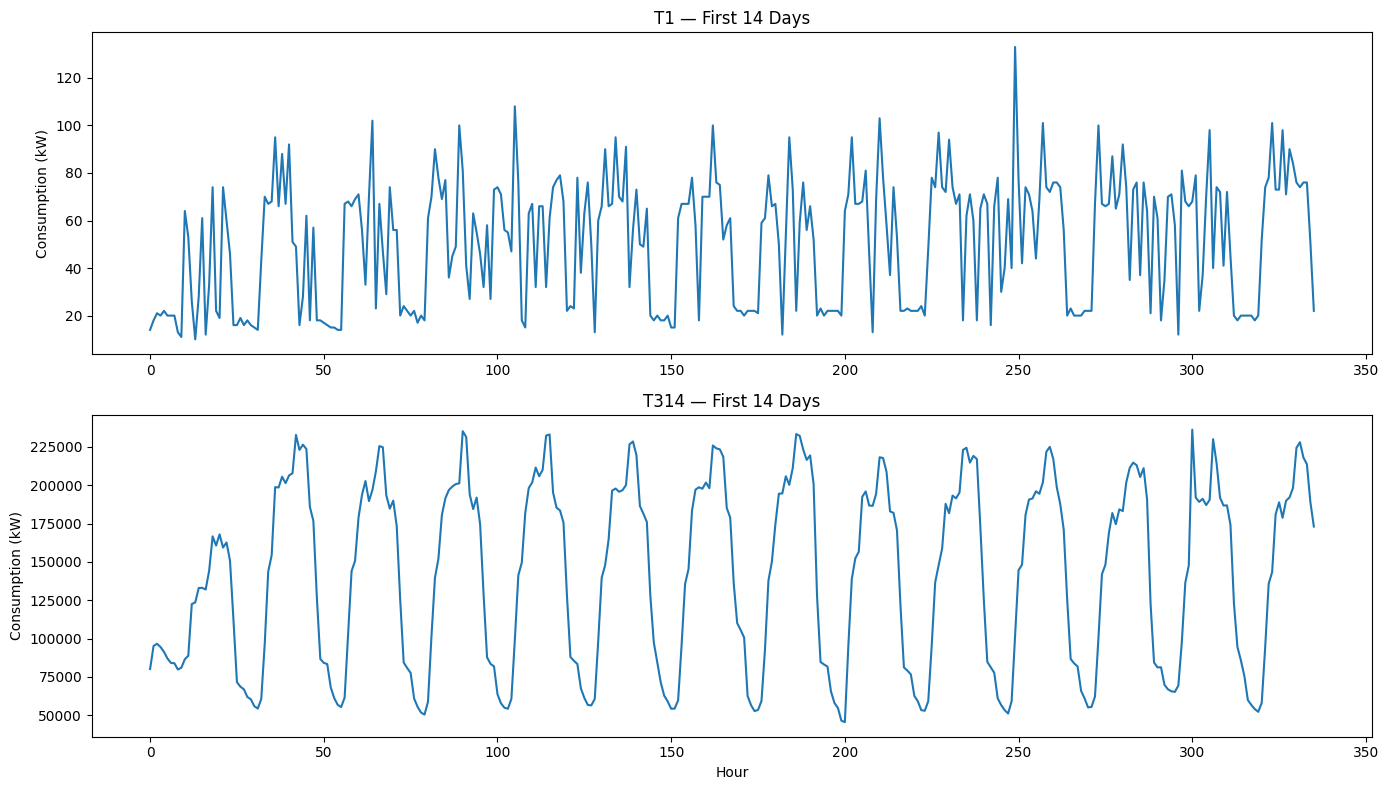

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Compare each customer's consumption on its own y-axis
axes[0].plot(series_data[0]["values"][:336])
axes[0].set_title("T1 — First 14 Days")
axes[0].set_ylabel("Consumption (kW)")

axes[1].plot(highest_series["values"][:336])
axes[1].set_title("T314 — First 14 Days")
axes[1].set_ylabel("Consumption (kW)")
axes[1].set_xlabel("Hour")

plt.tight_layout()
plt.show()

## 4. Chronological Train/Validation/Test Split

Each customer time series is divided chronologically into training, validation, and test sets. This preserves the temporal order of observations and prevents future data from being used to train the models.

The same split sizes are used for all 321 series:

| Split | Observations per series |
|---|---:|
| Training | 18,412 |
| Validation | 3,946 |
| Test | 3,946 |

The training set is used for fine-tuning, the validation set supports model selection and checkpoint selection, and the test set is reserved for final evaluation.

In [17]:
# Check how the dataset's starting timestamps are represented
print("Original timestamp:", series_data[0]["start_date"])

start_time = pd.to_datetime(
    series_data[0]["start_date"],
    format="%Y-%m-%d %H-%M-%S"
)

print("Parsed timestamp:", start_time)

# Calculate chronological split boundaries
n = len(series_data[0]["values"])

train_end = int(n * 0.70)
val_end = int(n * 0.85)

print("\nTotal observations:", n)
print("Training observations:", train_end)
print("Validation observations:", val_end - train_end)
print("Testing observations:", n - val_end)

Original timestamp: 2012-01-01 00-00-01
Parsed timestamp: 2012-01-01 00:00:01

Total observations: 26304
Training observations: 18412
Validation observations: 3946
Testing observations: 3946


In [18]:
# Split every customer's electricity consumption chronologically
train_data = []
val_data = []
test_data = []

for item in series_data:
    values = item["values"]

    train_data.append(values[:train_end])
    val_data.append(values[train_end:val_end])
    test_data.append(values[val_end:])

In [20]:
print(len(train_data), len(val_data), len(test_data))
print(len(train_data[0]), len(val_data[0]), len(test_data[0]))

321 321 321
18412 3946 3946


## 5. Saving the Prepared Dataset

The prepared training, validation, and test splits are saved as a compressed NumPy archive (`.npz`) in Google Drive.

This allows the subsequent notebooks to load and reuse the same data splits for zero-shot evaluation, LoRA fine-tuning, and final model evaluation without repeating the data preparation process.

In [21]:
np.savez_compressed(
    f"{save_dir}/dataset_splits.npz",
    train=np.array(train_data),
    val=np.array(val_data),
    test=np.array(test_data)
)

print("Dataset splits saved successfully")

Dataset splits saved successfully


In [23]:
print(os.path.exists(f"{save_dir}/dataset_splits.npz"))

True
